# 8. Componente espacial (2.7) y espacio-temporal (2.8)

Todo con el **periodo de entrenamiento**. Las distancias se calculan con la fórmula **haversine** (gran
círculo), nunca con distancia euclidiana sobre grados.

In [1]:
# Localiza la raíz del libro (la carpeta con _config.yml) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not (raiz / "_config.yml").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

In [2]:
# Catálogo y panel de entrenamiento para el análisis espacial
import plotly.graph_objects as go
from scipy.spatial import ConvexHull
from sklearn.cluster import DBSCAN
import warnings
warnings.filterwarnings("ignore")
ev_, X, info, tr, gp, te = datos.panel_completo()
P = datos.panel_dataframe(X, info, tr)
fin_tr = datos.fecha_de_mes(info["m_test"] - cfg.GAP_MESES)[0]
cat = ev_[ev_.time < fin_tr].copy()
rng = np.random.default_rng(cfg.SEMILLA)

## 8.1 Validación de coordenadas

In [3]:
# Validación de coordenadas: sistema de referencia, rangos y precisión
dec = cat.latitude.astype(str).str.split(".").str[-1].str.len()
val = pd.DataFrame([
    ("Sistema de referencia", "geográficas WGS84 (EPSG:4326), según los portales del SGC"),
    ("Latitud en [-90, 90] / longitud en [-180, 180]", "sí (100 %)"),
    ("Rango observado de latitud", f"{es(cat.latitude.min(), 2)} a {es(cat.latitude.max(), 2)}"),
    ("Rango observado de longitud", f"{es(cat.longitude.min(), 2)} a {es(cat.longitude.max(), 2)}"),
    ("Coordenadas nulas o (0, 0)", int(((cat.latitude == 0) & (cat.longitude == 0)).sum() + cat[["latitude", "longitude"]].isna().any(axis=1).sum())),
    ("Lat/lon invertidas (lat fuera de -5..14 con lon dentro de ese rango)", int((~cat.latitude.between(-5, 14) & cat.longitude.between(-5, 14)).sum())),
    ("Fuera del área de estudio", int((~cat.latitude.between(cfg.LAT_MIN, cfg.LAT_MAX) | ~cat.longitude.between(cfg.LON_MIN, cfg.LON_MAX)).sum())),
    ("Precisión (decimales de latitud, mediana)", f"{int(dec.median())} decimales (≈ {es(111 * 10 ** -dec.median() * 1000, 0)} m)"),
    ("Sismos con coordenadas exactamente repetidas", f"{int(cat.duplicated(['latitude', 'longitude']).sum())} ({es(cat.duplicated(['latitude', 'longitude']).mean(), 1, pct=True)})"),
], columns=["chequeo", "resultado"])
eda.guardar_tabla(val, "validacion_coordenadas.csv")
val

,chequeo,resultado
0,Sistema de referencia,"geográficas WGS84 (EPSG:4326), según los porta..."
1,"Latitud en [-90, 90] / longitud en [-180, 180]",sí (100 %)
2,Rango observado de latitud,"-2,65 a 13,67"
3,Rango observado de longitud,"-81,97 a -70,15"
4,"Coordenadas nulas o (0, 0)",0
5,Lat/lon invertidas (lat fuera de -5..14 con lo...,0
6,Fuera del área de estudio,0
7,"Precisión (decimales de latitud, mediana)",3 decimales (≈ 111 m)
8,Sismos con coordenadas exactamente repetidas,"4877 (16,6 %)"


In [4]:
md(f"""**Interpretación.**
- **Coordenadas válidas.** Están en grados geográficos (WGS84), sin nulos, ceros, inversiones ni puntos fuera del área.
- **Precisión.** Unos {int(dec.median())} decimales, del orden de cien metros. Es mayor que la incertidumbre real de la localización: el error
  mediano es de ≈ 3–5 km (capítulo 4), así que los decimales no implican exactitud.
- **Coordenadas repetidas.** El {es(cat.duplicated(['latitude', 'longitude']).mean(), 1, pct=True)} de los sismos repite exactamente las coordenadas de otro. Son
  sismos distintos que el localizador ubica en el mismo punto de la rejilla de búsqueda, casi todos en el nido. No son duplicados
  (sus fechas difieren).
- **Por qué celdas de 0,5° y no puntos.** Con errores de varios kilómetros, agregar en celdas de ≈ 55 km es más honesto que modelar
  puntos exactos.""")

**Interpretación.**
- **Coordenadas válidas.** Están en grados geográficos (WGS84), sin nulos, ceros, inversiones ni puntos fuera del área.
- **Precisión.** Unos 3 decimales, del orden de cien metros. Es mayor que la incertidumbre real de la localización: el error
  mediano es de ≈ 3–5 km (capítulo 4), así que los decimales no implican exactitud.
- **Coordenadas repetidas.** El 16,6 % de los sismos repite exactamente las coordenadas de otro. Son
  sismos distintos que el localizador ubica en el mismo punto de la rejilla de búsqueda, casi todos en el nido. No son duplicados
  (sus fechas difieren).
- **Por qué celdas de 0,5° y no puntos.** Con errores de varios kilómetros, agregar en celdas de ≈ 55 km es más honesto que modelar
  puntos exactos.

## 8.2 Visualización: mapa de puntos sobre mapa base, densidad y coropletas por celda

In [5]:
# Mapa interactivo de una muestra de sismos (tamaño = magnitud, color = profundidad)
m = cat.sample(6000, random_state=cfg.SEMILLA)
fig = go.Figure(go.Scattergeo(lat=m.latitude, lon=m.longitude, mode="markers",
                              marker=dict(size=3 + (m.mag - 2.5) * 2.5, color=m.depth, colorscale="Viridis_r", cmin=0, cmax=200,
                                          colorbar=dict(title="prof. (km)"), opacity=0.6),
                              text=[f"M {a:.1f} · {b:.0f} km · {t:%Y-%m-%d}" for a, b, t in zip(m.mag, m.depth, m.time)]))
fig.update_geos(lataxis_range=[-5, 14], lonaxis_range=[-82, -66], showcountries=True, countrycolor="#555",
                showcoastlines=True, showland=True, landcolor="#f7f7f2", showocean=True, oceancolor="#e6f0fa", resolution=50)
fig.update_layout(height=620, margin=dict(l=0, r=0, t=40, b=0), title="Sismos M ≥ 2,5 (muestra de 6.000 del entrenamiento; tamaño = magnitud, color = profundidad)")
mostrar_plotly(fig)

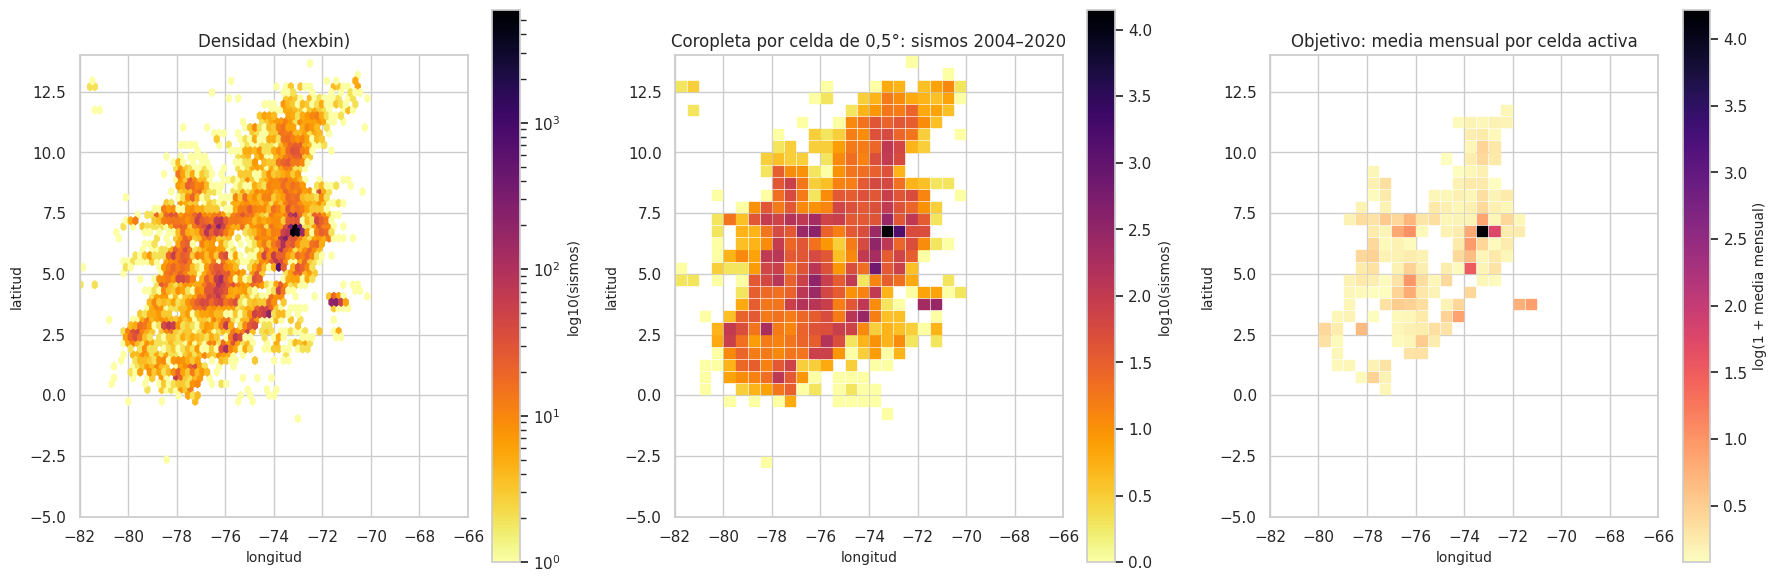

**Interpretación.**
- **Concentración extrema.** Los mapas muestran la sismicidad concentrada en el nido de Bucaramanga (Santander), el borde pacífico (Chocó,
  Valle, Nariño), el piedemonte llanero (Meta) y la región andina central.
- **Celdas con registro.** De las 1216 celdas de la rejilla, **400** registraron algún sismo en 2004–2020 y
  **163** cumplen el umbral de actividad (≥ 20 sismos) para entrar al panel.
- **El objetivo replica ese mapa.** La celda del nido promedia 67 sismos/mes, y la mayoría de las celdas activas, menos de uno.

In [6]:
# Densidad espacial (hexbin) y sismos por celda de 0,5°
n_lat, n_lon = datos.dimensiones_rejilla()
todos = cat.groupby("celda").size()
lat_c, lon_c = datos.centro_celda(todos.index)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
hb = axes[0].hexbin(cat.longitude, cat.latitude, gridsize=60, bins="log", cmap="inferno_r", mincnt=1)
plt.colorbar(hb, ax=axes[0], label="log10(sismos)"); axes[0].set_title("Densidad (hexbin)")
sc = axes[1].scatter(lon_c, lat_c, c=np.log10(todos.values), marker="s", s=55, cmap="inferno_r")
plt.colorbar(sc, ax=axes[1], label="log10(sismos)"); axes[1].set_title("Coropleta por celda de 0,5°: sismos 2004–2020")
act = P.groupby(["lat", "lon"]).y.mean().reset_index()
sc = axes[2].scatter(act.lon, act.lat, c=np.log1p(act.y), marker="s", s=55, cmap="magma_r")
plt.colorbar(sc, ax=axes[2], label="log(1 + media mensual)"); axes[2].set_title("Objetivo: media mensual por celda activa")
for ax in axes:
    ax.set_xlim(-82, -66); ax.set_ylim(-5, 14); ax.set_aspect("equal"); ax.set_xlabel("longitud"); ax.set_ylabel("latitud")
plt.tight_layout(); eda.guardar_figura(fig, "08_mapas.png"); plt.show()
md(f"""**Interpretación.**
- **Concentración extrema.** Los mapas muestran la sismicidad concentrada en el nido de Bucaramanga (Santander), el borde pacífico (Chocó,
  Valle, Nariño), el piedemonte llanero (Meta) y la región andina central.
- **Celdas con registro.** De las {n_lat * n_lon} celdas de la rejilla, **{len(todos)}** registraron algún sismo en 2004–2020 y
  **{len(info['celdas'])}** cumplen el umbral de actividad (≥ 20 sismos) para entrar al panel.
- **El objetivo replica ese mapa.** La celda del nido promedia {es(act.y.max(), 0)} sismos/mes, y la mayoría de las celdas activas, menos de uno.""")

## 8.3 Patrón de puntos y cobertura

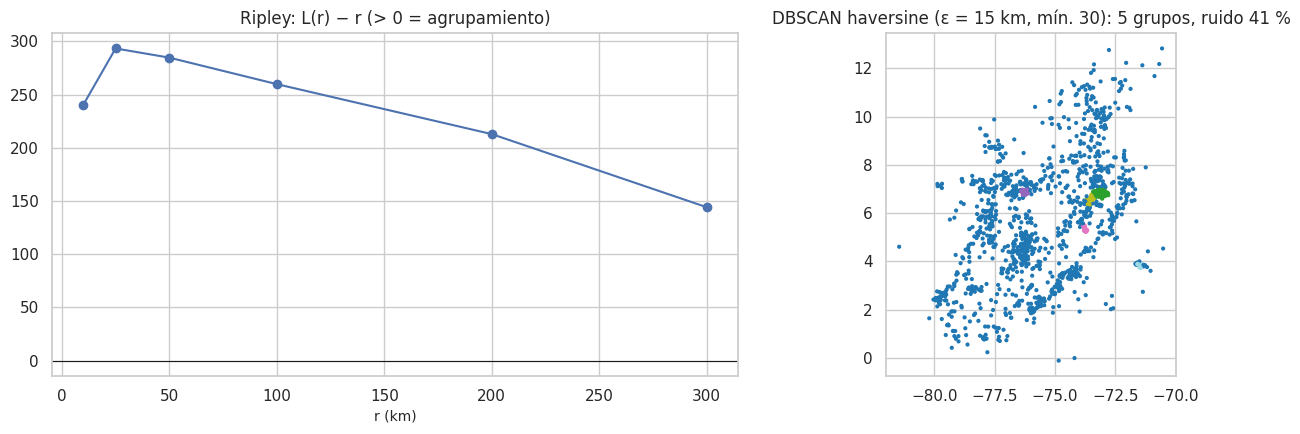

,R,dist_media_obs_km,dist_esperada_km,z,p
0,0.473,4.786,10.119,-55.228,0.0


,sismos,lat,lon,prof_mediana
cluster,,,,
0,1564,6.82,-73.12,146.61
2,71,5.28,-73.74,146.50
3,61,6.56,-73.53,111.20
1,34,6.89,-76.27,0.00
4,30,3.85,-71.45,2.00


In [7]:
# Patrón de puntos: Clark-Evans, Ripley L y agrupamientos DBSCAN
s = cat.sample(3000, random_state=cfg.SEMILLA)
xy = np.column_stack([np.radians(s.longitude) * 6371 * np.cos(np.radians(6)), np.radians(s.latitude) * 6371])
area = ConvexHull(xy).volume                                  # área (km²) de la envolvente convexa, proyección local
ce = eda.clark_evans(s.latitude, s.longitude, area)
rip = eda.ripley_l(s.latitude, s.longitude, [10, 25, 50, 100, 200, 300], area)
db = DBSCAN(eps=15 / 6371.0088, min_samples=30, metric="haversine").fit(np.radians(s[["latitude", "longitude"]]))
s["cluster"] = db.labels_
cl = s[s.cluster >= 0].groupby("cluster").agg(sismos=("mag", "size"), lat=("latitude", "median"), lon=("longitude", "median"),
                                             prof_mediana=("depth", "median")).sort_values("sismos", ascending=False)
eda.guardar_tabla(rip, "ripley.csv"); eda.guardar_tabla(cl.reset_index(), "dbscan_clusters.csv")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(rip.r_km, rip.L_menos_r, "o-"); axes[0].axhline(0, c="k", lw=0.8); axes[0].set_title("Ripley: L(r) − r (> 0 = agrupamiento)"); axes[0].set_xlabel("r (km)")
axes[1].scatter(s.longitude, s.latitude, c=np.where(s.cluster >= 0, s.cluster, -1), cmap="tab20", s=4)
axes[1].set_aspect("equal"); axes[1].set_title(f"DBSCAN haversine (ε = 15 km, mín. 30): {len(cl)} grupos, ruido {es((s.cluster < 0).mean(), 0, pct=True)}")
plt.tight_layout(); eda.guardar_figura(fig, "08_patron_puntos.png"); plt.show()
display(pd.DataFrame([ce]).round(3))
cl.head(8).round(2)

In [8]:
# Celdas sin cobertura para la interpretación
sin_cob = n_lat * n_lon - len(todos)
md(f"""**Interpretación.**
- **Clark-Evans: patrón agrupado.** R = {es(ce['R'], 3)} (R < 1 indica agrupamiento; z = {es(ce['z'], 1)}, p {p_fmt(ce['p'])}): la distancia media al vecino más
  cercano es {es(ce['dist_media_obs_km'], 1)} km, frente a {es(ce['dist_esperada_km'], 1)} km esperados si los sismos estuvieran repartidos al azar en el mismo
  territorio.
- **Ripley.** L(r) − r es positiva en todas las escalas: hay agrupamiento desde 10 km hasta cientos de km (focos dentro de regiones
  activas). Como se calcula sin corrección de borde, los valores a gran escala (exceso de hasta {es(rip.L_menos_r.max(), 0)} km) son una cota
  superior; lo robusto es el signo, positivo ya desde 10 km.
- **DBSCAN (distancia haversine).** Encuentra {len(cl)} grupos. El mayor, con {es(cl.sismos.iloc[0] / len(s), 0, pct=True)} de la muestra y profundidad
  mediana {es(cl.prof_mediana.iloc[0], 0)} km, es el **nido de Bucaramanga**.
- **Cobertura.** {sin_cob} de las {n_lat * n_lon} celdas de la rejilla nunca registran un sismo. Una parte es mar, pero otra es territorio con
  pocas estaciones (Amazonía, Orinoquía): ahí la ausencia mezcla **baja sismicidad real** con **menor detección**, un sesgo de muestreo
  espacial que el modelo no puede corregir y que justifica no extrapolarlo a zonas sin historia.""")

**Interpretación.**
- **Clark-Evans: patrón agrupado.** R = 0,473 (R < 1 indica agrupamiento; z = -55,2, p < 0,001): la distancia media al vecino más
  cercano es 4,8 km, frente a 10,1 km esperados si los sismos estuvieran repartidos al azar en el mismo
  territorio.
- **Ripley.** L(r) − r es positiva en todas las escalas: hay agrupamiento desde 10 km hasta cientos de km (focos dentro de regiones
  activas). Como se calcula sin corrección de borde, los valores a gran escala (exceso de hasta 293 km) son una cota
  superior; lo robusto es el signo, positivo ya desde 10 km.
- **DBSCAN (distancia haversine).** Encuentra 5 grupos. El mayor, con 52 % de la muestra y profundidad
  mediana 147 km, es el **nido de Bucaramanga**.
- **Cobertura.** 816 de las 1216 celdas de la rejilla nunca registran un sismo. Una parte es mar, pero otra es territorio con
  pocas estaciones (Amazonía, Orinoquía): ahí la ausencia mezcla **baja sismicidad real** con **menor detección**, un sesgo de muestreo
  espacial que el modelo no puede corregir y que justifica no extrapolarlo a zonas sin historia.

## 8.4 Autocorrelación espacial: I de Moran, LISA y Getis-Ord Gi*

- **Variable:** media de log(1 + y) por celda activa (entrenamiento).
- **Matriz de pesos:** **k = 8 vecinos más cercanos** por distancia haversine, estandarizada por filas.
  Es el equivalente de la contigüidad tipo reina en una rejilla regular (8 vecinos) y garantiza que
  ninguna celda quede aislada, porque las celdas activas no forman una rejilla completa. Como
  sensibilidad se repite con una banda de 120 km.

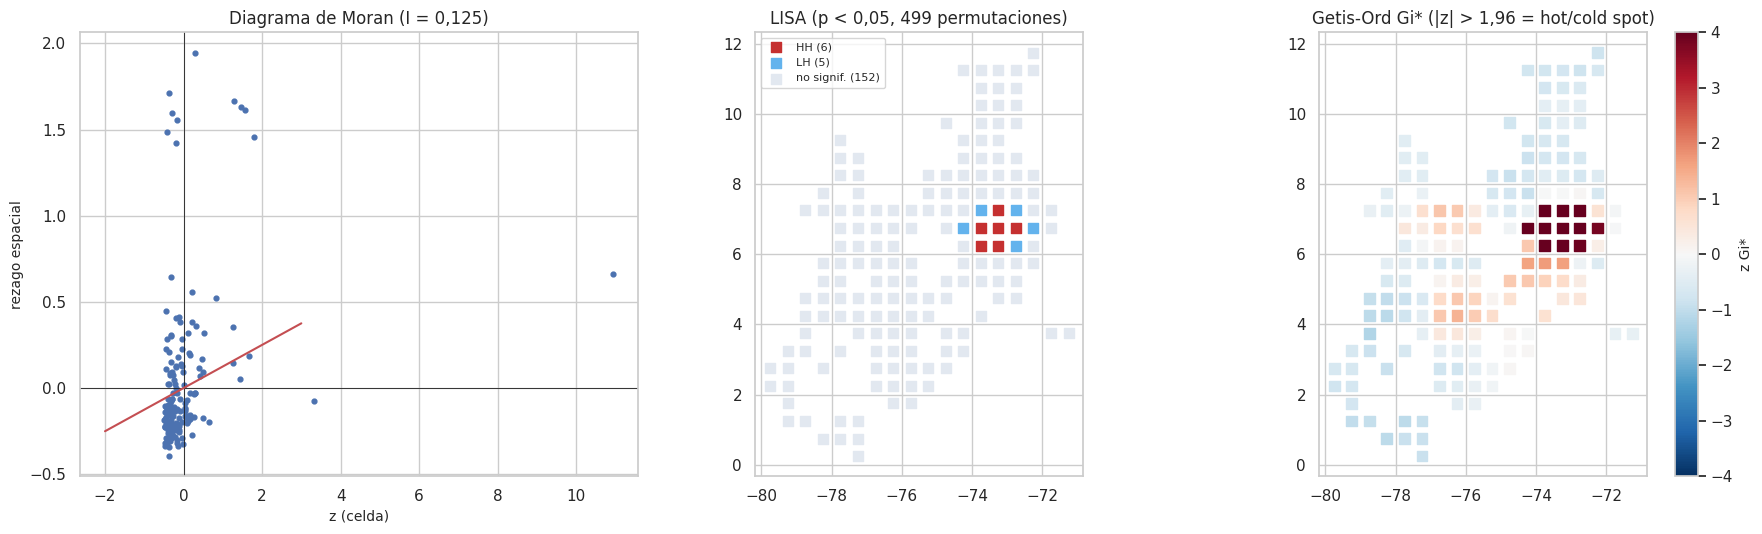

,pesos,I,E[I],z,p
0,kNN k=8,0.1252,-0.0062,5.5847,0.001
1,banda 120 km,0.0967,-0.0062,3.8188,0.005


In [9]:
# Autocorrelación espacial: I de Moran global (k vecinos y banda de distancia) y LISA local
pc = P.groupby("celda").agg(lat=("lat", "first"), lon=("lon", "first"), v=("log_y", "mean")).reset_index()
W = eda.pesos_knn(pc.lat, pc.lon, k=8)
Wb = eda.pesos_banda(pc.lat, pc.lon, 120)
mg = eda.moran_global(pc.v, W)
mg_b = eda.moran_global(pc.v[Wb.sum(1) > 0], Wb[np.ix_(Wb.sum(1) > 0, Wb.sum(1) > 0)])
lisa = eda.moran_local(pc.v, W, permutaciones=499)
pc = pd.concat([pc, lisa], axis=1)
pc["Gi"] = eda.getis_ord_gi(pc.v, W)
pc["tipo"] = np.where(pc.p < 0.05, pc.cuadrante, "no signif.")
eda.guardar_tabla(pd.DataFrame([{"pesos": "kNN k=8", **mg}, {"pesos": "banda 120 km", **mg_b}]), "moran_global.csv")
eda.guardar_tabla(pc, "lisa_gi_celdas.csv")
colores = {"HH": "#c53030", "LL": "#2b6cb0", "HL": "#ed8936", "LH": "#63b3ed", "no signif.": "#e2e8f0"}
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
axes[0].scatter(pc.z, pc.rezago, s=12); axes[0].axhline(0, c="k", lw=0.6); axes[0].axvline(0, c="k", lw=0.6)
axes[0].plot([-2, 3], np.array([-2, 3]) * mg["I"], c="r"); axes[0].set_title(f"Diagrama de Moran (I = {es(mg['I'], 3)})")
axes[0].set_xlabel("z (celda)"); axes[0].set_ylabel("rezago espacial")
for t_, d in pc.groupby("tipo"):
    axes[1].scatter(d.lon, d.lat, c=colores[t_], marker="s", s=60, label=f"{t_} ({len(d)})")
axes[1].legend(fontsize=8); axes[1].set_title("LISA (p < 0,05, 499 permutaciones)")
sc = axes[2].scatter(pc.lon, pc.lat, c=pc.Gi, cmap="RdBu_r", vmin=-4, vmax=4, marker="s", s=60)
plt.colorbar(sc, ax=axes[2], label="z Gi*"); axes[2].set_title("Getis-Ord Gi* (|z| > 1,96 = hot/cold spot)")
for ax in axes[1:]:
    ax.set_aspect("equal")
plt.tight_layout(); eda.guardar_figura(fig, "08_moran_lisa_gi.png"); plt.show()
pd.DataFrame([{"pesos": "kNN k=8", **mg}, {"pesos": "banda 120 km", **mg_b}]).round(4)

In [10]:
md(f"""**Interpretación.**
- **Autocorrelación global.** El I de Moran global es **{es(mg['I'], 3)}** (E[I] = {es(mg['E[I]'], 3)}, z = {es(mg['z'], 1)}, p por permutación = {p_fmt(mg['p'])}):
  las celdas activas tienen vecinas activas. Con la banda de 120 km el resultado es parecido (I = {es(mg_b['I'], 3)}): no depende de la
  matriz de pesos.
- **Intensidad.** La autocorrelación es positiva pero **moderada**: la mayor parte de la variación entre celdas no se explica por sus vecinas.
- **LISA.** Identifica {int((pc.tipo == 'HH').sum())} celdas **alto-alto** significativas (lat {es(pc[pc.tipo == 'HH'].lat.min(), 2)}–{es(pc[pc.tipo == 'HH'].lat.max(), 2)},
  lon {es(pc[pc.tipo == 'HH'].lon.min(), 2)} a {es(pc[pc.tipo == 'HH'].lon.max(), 2)}: el nido y su entorno), {int((pc.tipo == 'LL').sum())} bajo-bajo y
  {int(pc.tipo.isin(['HL', 'LH']).sum())} atípicas espaciales (HL/LH). Que no haya clústeres bajo-bajo significativos es lógico: casi todas las celdas
  activas tienen actividad baja, así que una celda tranquila rodeada de celdas tranquilas no se aparta de lo esperado.
- **Gi\\*.** {int((pc.Gi > 1.96).sum())} hot spots (z > 1,96), en lat {es(pc[pc.Gi > 1.96].lat.min(), 2)}–{es(pc[pc.Gi > 1.96].lat.max(), 2)} y lon
  {es(pc[pc.Gi > 1.96].lon.min(), 2)} a {es(pc[pc.Gi > 1.96].lon.max(), 2)}: coinciden con el núcleo HH de LISA.
- **Implicación.** La dependencia espacial positiva justifica la variable de **rezago espacial** (`vec_1m`, `vec_3m`) y advierte que una
  validación cruzada aleatoria entre celdas sería optimista. Además, los residuos del modelo deben revisarse con el I de Moran
  (capítulo 11).
- **Semivariograma.** No aplica: los datos son conteos agregados por áreas (celdas), no una variable continua medida en puntos. La
  dependencia espacial se describe con Moran y LISA, que son los métodos adecuados para datos de área.""")

**Interpretación.**
- **Autocorrelación global.** El I de Moran global es **0,125** (E[I] = -0,006, z = 5,6, p por permutación = 0,001):
  las celdas activas tienen vecinas activas. Con la banda de 120 km el resultado es parecido (I = 0,097): no depende de la
  matriz de pesos.
- **Intensidad.** La autocorrelación es positiva pero **moderada**: la mayor parte de la variación entre celdas no se explica por sus vecinas.
- **LISA.** Identifica 6 celdas **alto-alto** significativas (lat 6,25–7,25,
  lon -73,75 a -72,75: el nido y su entorno), 0 bajo-bajo y
  5 atípicas espaciales (HL/LH). Que no haya clústeres bajo-bajo significativos es lógico: casi todas las celdas
  activas tienen actividad baja, así que una celda tranquila rodeada de celdas tranquilas no se aparta de lo esperado.
- **Gi\*.** 11 hot spots (z > 1,96), en lat 6,25–7,25 y lon
  -74,25 a -72,25: coinciden con el núcleo HH de LISA.
- **Implicación.** La dependencia espacial positiva justifica la variable de **rezago espacial** (`vec_1m`, `vec_3m`) y advierte que una
  validación cruzada aleatoria entre celdas sería optimista. Además, los residuos del modelo deben revisarse con el I de Moran
  (capítulo 11).
- **Semivariograma.** No aplica: los datos son conteos agregados por áreas (celdas), no una variable continua medida en puntos. La
  dependencia espacial se describe con Moran y LISA, que son los métodos adecuados para datos de área.

## 8.5 Heterogeneidad espacial y efecto de la escala (MAUP)

In [11]:
# Sensibilidad del I de Moran al tamaño de celda
def moran_por_escala(tam):
    c_ = datos.asignar_celda(cat.latitude, cat.longitude, tam)
    meses = cat.mes.nunique()
    cnt = pd.Series(c_).value_counts()
    cnt = cnt[cnt >= 20]
    la, lo = datos.centro_celda(cnt.index.to_numpy(), tam)
    v = np.log1p(cnt.values / meses)
    return {"celda_grados": tam, "celdas_con_>=20_sismos": len(cnt), **eda.moran_global(v, eda.pesos_knn(la, lo, 8), permutaciones=499)}
maup = pd.DataFrame([moran_por_escala(t_) for t_ in (0.25, 0.5, 1.0)])
eda.guardar_tabla(maup, "maup_moran.csv")
P["region"] = np.select([(P.lat == 6.75) & (P.lon == -73.25), P.lon < -76, P.lat < 3.5, P.lat > 8.5],
                        ["nido Bucaramanga", "Pacífico (lon < -76)", "Sur (lat < 3,5)", "Caribe (lat > 8,5)"], "Andes centrales")
het = P.groupby("region").apply(lambda g: pd.Series({"celdas": g.celda.nunique(), "media_y": g.y.mean(),
                                                     "pendiente log y ~ log n_1m": np.polyfit(np.log1p(g.n_1m), g.log_y, 1)[0],
                                                     "Spearman(y, vec_1m)": stats.spearmanr(g.y, g.vec_1m)[0]}))
eda.guardar_tabla(het.reset_index(), "heterogeneidad_regional.csv")
display(maup.round(4))
het.round(3)

,celda_grados,celdas_con_>=20_sismos,I,E[I],z,p
0,0.25,181,0.1886,-0.0056,7.7600,0.002
1,0.50,163,0.1554,-0.0062,5.8535,0.002
2,1.00,78,0.1807,-0.0130,4.4393,0.002


,celdas,media_y,pendiente log y ~ log n_1m,"Spearman(y, vec_1m)"
region,,,,
Andes centrales,60.0,0.494,0.454,0.147
"Caribe (lat > 8,5)",23.0,0.218,0.112,0.122
Pacífico (lon < -76),70.0,0.363,0.281,0.195
"Sur (lat < 3,5)",9.0,0.517,0.231,0.016
nido Bucaramanga,1.0,66.958,0.336,0.200


In [12]:
md(f"""**Interpretación.**
- **MAUP.** El I de Moran cambia con el tamaño de celda: {', '.join(f"{es(r.I, 2)} con {r.celda_grados}°" for r in maup.itertuples())}.
  La conclusión (autocorrelación positiva) se mantiene en las tres escalas; lo que cambia es su intensidad.
  - Celdas más pequeñas dan más unidades, pero con más ceros y más error de localización relativo.
  - Celdas más grandes mezclan focos distintos.
  - **0,5°** es un compromiso: del orden del error de localización multiplicado por diez y del tamaño de los focos de DBSCAN.
- **Heterogeneidad regional.** La relación entre el conteo del mes previo y el del mes siguiente **cambia con la ubicación**. La pendiente
  va de {es(het['pendiente log y ~ log n_1m'].min(), 2)} a {es(het['pendiente log y ~ log n_1m'].max(), 2)} entre regiones, y la asociación con la vecindad también
  varía. Un único coeficiente lineal global es una simplificación, y esto anticipa que los modelos no lineales del Entregable 2 aprovechen las
  interacciones con la ubicación.
- **Ingeniería de características espaciales (cap. 10).**
  - **Celdas:** la unidad de análisis.
  - **Rezago espacial:** sismos en las 8 celdas vecinas (`vec_1m`, `vec_3m`).
  - **Latitud y longitud del centro de la celda**, como variables crudas. Se justifican porque la relación con la ubicación es no
    monótona (capítulo 5, información mutua) y solo se pronostica en las mismas celdas. No se usan para extrapolar a zonas nuevas.
  - En el Entregable 2 se añaden **intensidades de excitación** con núcleo de distancia haversine (tipo ETAS).""")

**Interpretación.**
- **MAUP.** El I de Moran cambia con el tamaño de celda: 0,19 con 0.25°, 0,16 con 0.5°, 0,18 con 1.0°.
  La conclusión (autocorrelación positiva) se mantiene en las tres escalas; lo que cambia es su intensidad.
  - Celdas más pequeñas dan más unidades, pero con más ceros y más error de localización relativo.
  - Celdas más grandes mezclan focos distintos.
  - **0,5°** es un compromiso: del orden del error de localización multiplicado por diez y del tamaño de los focos de DBSCAN.
- **Heterogeneidad regional.** La relación entre el conteo del mes previo y el del mes siguiente **cambia con la ubicación**. La pendiente
  va de 0,11 a 0,45 entre regiones, y la asociación con la vecindad también
  varía. Un único coeficiente lineal global es una simplificación, y esto anticipa que los modelos no lineales del Entregable 2 aprovechen las
  interacciones con la ubicación.
- **Ingeniería de características espaciales (cap. 10).**
  - **Celdas:** la unidad de análisis.
  - **Rezago espacial:** sismos en las 8 celdas vecinas (`vec_1m`, `vec_3m`).
  - **Latitud y longitud del centro de la celda**, como variables crudas. Se justifican porque la relación con la ubicación es no
    monótona (capítulo 5, información mutua) y solo se pronostica en las mismas celdas. No se usan para extrapolar a zonas nuevas.
  - En el Entregable 2 se añaden **intensidades de excitación** con núcleo de distancia haversine (tipo ETAS).

## 8.6 Consecuencias para el modelado (2.7)

- **Validación cruzada.** Como celdas cercanas se parecen (Moran > 0), una validación cruzada aleatoria
  entre celdas sería optimista. El objetivo del proyecto es **pronosticar el futuro en las mismas
  celdas**, así que la validación principal es temporal (capítulo 7).
- **Esquema espacial adicional.** Para medir la generalización a zonas no vistas, el capítulo 11 reporta
  por separado una **validación por bloques espaciales**: `GroupKFold` con bloques de 2° × 2° y un
  **buffer** que excluye del entrenamiento las celdas vecinas del bloque de validación.

# Componente espacio-temporal (2.8)

## 8.7 Mapas por periodo y series por zona

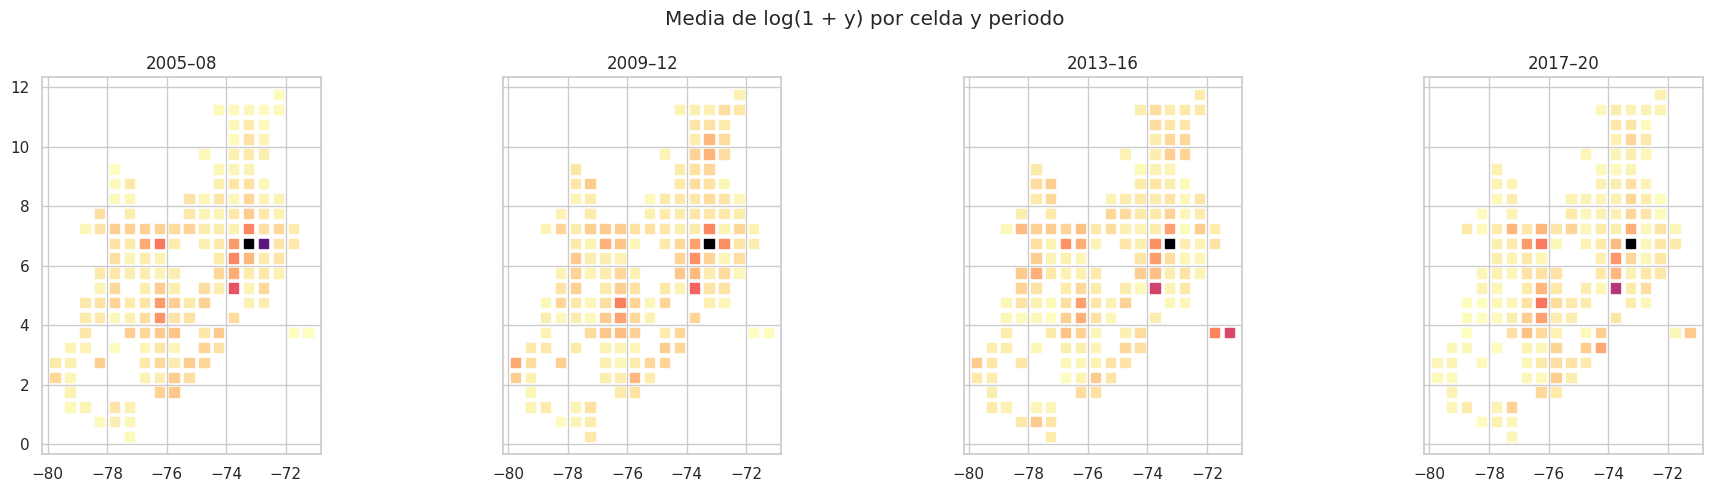

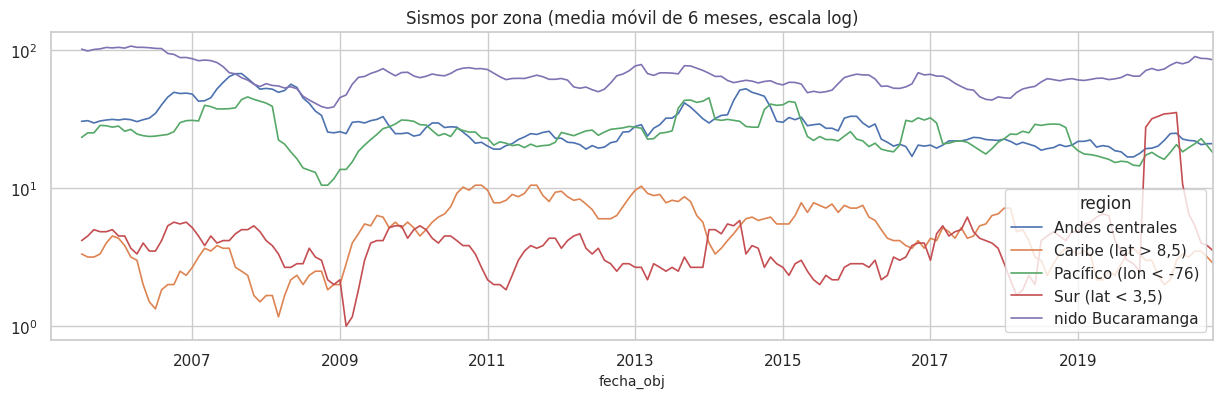

**Interpretación.**
- **Mapas por periodo.** El patrón espacial es **estable a grandes rasgos**: el nido y los focos principales aparecen en los cuatro periodos.
  Algunas celdas se encienden o apagan entre periodos (enjambres).
- **Series por zona.**
  - El nido domina el total y tiene un nivel alto y persistente.
  - Las demás zonas tienen niveles uno o dos órdenes de magnitud menores y episodios propios.
  - La correlación entre las series de distintas zonas es baja
    (|ρ| medio = 0,11): cada zona tiene su dinámica.

In [13]:
# Estabilidad espacial: actividad media por celda en cuatro periodos
P["periodo"] = pd.cut(P.fecha_obj.dt.year, [2004, 2008, 2012, 2016, 2020], labels=["2005–08", "2009–12", "2013–16", "2017–20"])
fig, axes = plt.subplots(1, 4, figsize=(19, 5), sharey=True)
for ax, (per, g) in zip(axes, P.groupby("periodo")):
    a = g.groupby(["lat", "lon"]).log_y.mean().reset_index()
    ax.scatter(a.lon, a.lat, c=a.log_y, cmap="magma_r", vmin=0, vmax=3.5, marker="s", s=45)
    ax.set_title(f"{per}"); ax.set_aspect("equal")
plt.suptitle("Media de log(1 + y) por celda y periodo"); plt.tight_layout(); eda.guardar_figura(fig, "08_mapas_periodo.png"); plt.show()
zonas = P.groupby(["fecha_obj", "region"]).y.sum().unstack()
fig, ax = plt.subplots(figsize=(15, 4))
(zonas.rolling(6).mean()).plot(ax=ax, lw=1.2, logy=True)
ax.set_title("Sismos por zona (media móvil de 6 meses, escala log)"); eda.guardar_figura(fig, "08_series_zona.png"); plt.show()
md(f"""**Interpretación.**
- **Mapas por periodo.** El patrón espacial es **estable a grandes rasgos**: el nido y los focos principales aparecen en los cuatro periodos.
  Algunas celdas se encienden o apagan entre periodos (enjambres).
- **Series por zona.**
  - El nido domina el total y tiene un nivel alto y persistente.
  - Las demás zonas tienen niveles uno o dos órdenes de magnitud menores y episodios propios.
  - La correlación entre las series de distintas zonas es {('baja' if zonas.corr().where(~np.eye(zonas.shape[1], dtype=bool)).abs().mean().mean() < 0.3 else 'moderada')}
    (|ρ| medio = {es(zonas.corr().where(~np.eye(zonas.shape[1], dtype=bool)).abs().mean().mean(), 2)}): cada zona tiene su dinámica.""")

## 8.8 Interacción espacio-tiempo: prueba de Knox y persistencia de hotspots

- **Prueba de Knox** {cite}`knox1964detection`: cuenta los pares de sismos cercanos **a la vez** en
  espacio (≤ 25 km) y en tiempo (≤ 30 días), y compara ese número con lo esperado si los tiempos se
  permutan al azar. Se aplica sobre 2.500 sismos (499 permutaciones). Se repite **excluyendo el
  nido**, porque su actividad casi constante podría dominar el resultado.
- **Persistencia de hotspots:** Gi* por año y similitud de Jaccard entre los conjuntos de hotspots de
  años consecutivos.

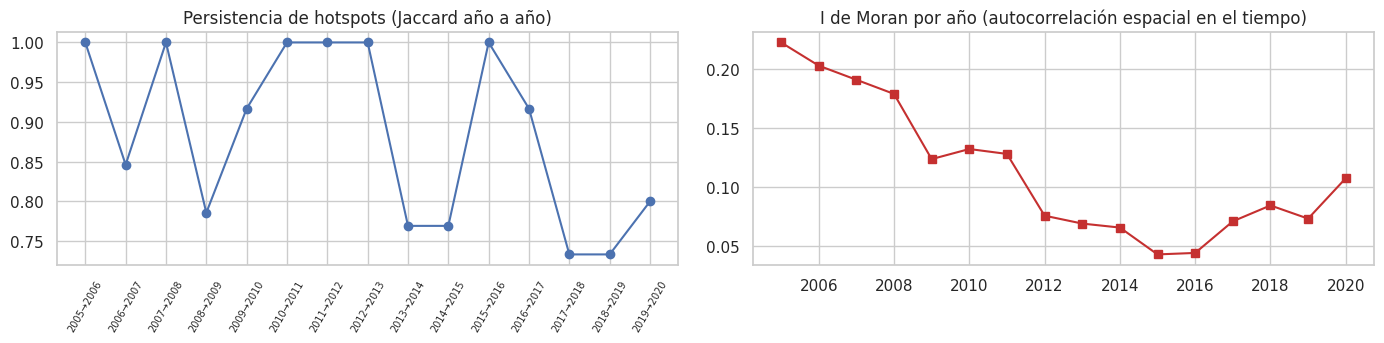

,muestra,pares_observados,pares_esperados,razon,p
0,todos,9214,8283.8096,1.1123,0.002
1,sin el nido,2150,510.2605,4.2135,0.002


In [14]:
# Interacción espacio-tiempo: prueba de Knox, con y sin el nido de Bucaramanga
s_k = cat.sample(2500, random_state=cfg.SEMILLA)
t_dias = (s_k.time - s_k.time.min()).dt.total_seconds() / 86400
knox = eda.prueba_knox(s_k.latitude, s_k.longitude, t_dias, 25, 30)
fuera = cat[~((cat.latitude.between(6.5, 7.0)) & (cat.longitude.between(-73.5, -73.0)))].sample(2500, random_state=cfg.SEMILLA)
knox_f = eda.prueba_knox(fuera.latitude, fuera.longitude, (fuera.time - fuera.time.min()).dt.total_seconds() / 86400, 25, 30)
kn = pd.DataFrame([{"muestra": "todos", **knox}, {"muestra": "sin el nido", **knox_f}])
eda.guardar_tabla(kn, "knox.csv")
hot = {}
for anio, g in P.groupby(P.fecha_obj.dt.year):
    a = g.groupby("celda").agg(lat=("lat", "first"), lon=("lon", "first"), v=("log_y", "mean"))
    gi = eda.getis_ord_gi(a.v.to_numpy(), eda.pesos_knn(a.lat, a.lon, 8))
    hot[anio] = set(a.index[gi > 1.96])
anios = sorted(hot)
jac = pd.DataFrame([{"años": f"{a}→{b}", "hotspots_a": len(hot[a]), "hotspots_b": len(hot[b]),
                     "Jaccard": len(hot[a] & hot[b]) / max(len(hot[a] | hot[b]), 1)} for a, b in zip(anios[:-1], anios[1:])])
moran_anual = pd.DataFrame([{"año": anio, **eda.moran_global(g.groupby("celda").log_y.mean().to_numpy(),
                             eda.pesos_knn(g.groupby("celda").lat.first(), g.groupby("celda").lon.first(), 8), permutaciones=199)}
                            for anio, g in P.groupby(P.fecha_obj.dt.year)])
eda.guardar_tabla(jac, "persistencia_hotspots.csv"); eda.guardar_tabla(moran_anual, "moran_por_anio.csv")
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
axes[0].plot(jac["años"], jac.Jaccard, "o-"); axes[0].set_title("Persistencia de hotspots (Jaccard año a año)"); axes[0].tick_params(axis="x", rotation=60, labelsize=7)
axes[1].plot(moran_anual["año"], moran_anual.I, "s-", c="#c53030"); axes[1].set_title("I de Moran por año (autocorrelación espacial en el tiempo)")
plt.tight_layout(); eda.guardar_figura(fig, "08_hotspots_tiempo.png"); plt.show()
kn.round(4)

In [15]:
md(f"""**Interpretación.**
- **Knox (con el nido).** Hay **{es(kn.razon[0], 2)} veces** más pares cercanos en espacio y tiempo de lo esperado sin interacción
  (p = {es(kn.p[0], 3)}).
- **Knox (sin el nido).** La razón sube a **{es(kn.razon[1], 2)}** (p = {es(kn.p[1], 3)}): fuera del nido los sismos llegan claramente **agrupados en
  espacio-tiempo** (réplicas y enjambres). Esta es la interacción que modelan los procesos de autoexcitación tipo ETAS.
- **Hotspots.** El conjunto de hotspots es **muy persistente**: Jaccard medio entre años consecutivos = {es(jac.Jaccard.mean(), 2)}, con
  {es(np.mean([len(v) for v in hot.values()]), 1)} hotspots por año en promedio. Los hotspots **no se desplazan**; aparecen y desaparecen focos
  secundarios alrededor de un núcleo fijo.
- **Autocorrelación espacio-temporal.** El I de Moran anual es positivo todos los años (entre {es(moran_anual.I.min(), 2)} y {es(moran_anual.I.max(), 2)}): la
  dependencia espacial es estable en el tiempo.""")

**Interpretación.**
- **Knox (con el nido).** Hay **1,11 veces** más pares cercanos en espacio y tiempo de lo esperado sin interacción
  (p = 0,002).
- **Knox (sin el nido).** La razón sube a **4,21** (p = 0,002): fuera del nido los sismos llegan claramente **agrupados en
  espacio-tiempo** (réplicas y enjambres). Esta es la interacción que modelan los procesos de autoexcitación tipo ETAS.
- **Hotspots.** El conjunto de hotspots es **muy persistente**: Jaccard medio entre años consecutivos = 0,88, con
  11,9 hotspots por año en promedio. Los hotspots **no se desplazan**; aparecen y desaparecen focos
  secundarios alrededor de un núcleo fijo.
- **Autocorrelación espacio-temporal.** El I de Moran anual es positivo todos los años (entre 0,04 y 0,22): la
  dependencia espacial es estable en el tiempo.

## 8.9 Consecuencias para el modelado (2.8) e interpretación

- **Objetivo de generalización: el futuro en las mismas celdas.** Por eso:
  - la partición principal es **cronológica**: entrenamiento hasta noviembre de 2020, gap de un mes y
    prueba desde enero de 2021;
  - la validación cruzada es **temporal de ventana creciente** con gap.
- **Generalización a zonas nuevas.** Se reporta **por separado** con bloques espaciales y buffer
  (capítulo 11), como diagnóstico. No es el uso previsto del modelo.
- **Riesgos de fuga por vecindad.**
  - **En el tiempo:** las variables del mes *t* comparten sismos con el objetivo de *t* + 1 si la ventana
    se solapara. Se evita porque las ventanas terminan en *t*, y con el gap entre conjuntos.
  - **En el espacio:** el rezago espacial usa vecinos **en el mismo mes *t***, nunca en *t* + 1.
- **Dinámica.** La sismicidad combina un **fondo espacial estable** (hotspots persistentes) con
  **episodios agrupados en espacio-tiempo** (Knox). Un buen modelo debe tener ambas piezas: la historia
  larga de la celda y la excitación reciente de la celda y de sus vecinas.